# PHYS 763 HW3b: First Qolab Experiments
Fall 2026 — due October 15. **30 points**, separate from written HW3 (due October 12).

Collect your own Power Rabi and T1 data using the QUAlibrate browser interface and the settings in the handout. Start the interface with `uv run qualibrate start`, then open `http://127.0.0.1:8001` (the default address) in a web browser on the same computer. Keep the terminal running while using the interface.

This starter analysis notebook is provided with HW3b. It only reads saved data: it does not connect to the backend, launch experiments, or update calibration state.

Use the Qolab Python environment as the notebook kernel. Save your raw data and experiment parameters with your submission. Do not submit access tokens, credentials, or screenshots containing them. Automated Qolab results are comparisons, not substitutes for your own fits.

In [1]:
from pathlib import Path
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

## 1. Experimental record
Record the repository commit, qubit names, run IDs, dates/times, shots per point, sweep settings and units, reset mode, and local state updates. Use two working qubits, the same two for Rabi and T1.

| Run | Rep Commit |Qubit Node | Run ID / time | Shots per point | Sweep / units | Reset / state changes |
| --- | --- | --- | --- | --- | --- | --- |
| Rabi 1 |15951f8 |Q4 | 2026-10-11 23:16:20| 100 |0 to 1.5 step 0.05 |thermal |
| Rabi 2 |15951f8 |Q6 | 2026-10-11 23:21:29| 100 |0 to 1.5 step 0.05| thermal |
| T1 1 |fdbea14| Q4|2026-10-12 12:37:13 |100 | 16ns to 200$\mu$s with 100 points, linear sweep  |thermal |
| T1 2 |fdbea14| Q6|2026-10-13 12:41:09 |100| 16ns to 200$\mu$s with 100 points, linear sweep|thermal|
| T1 repeat |fdbea14|Q6 |2026-10-13 12:44:59|400 | 16ns to 200$\mu$s with 100 points, linear sweep|thermal |

Your experiment runs generate the raw datasets (`ds_raw.h5`); they are not supplied with the homework. The data live in your active QUAlibrate project's storage directory. In the current checkout, the standard project is under `qualibration_graphs/superconducting/calibrations/1Q_calibrations/`. Use the raw dataset listed in the saved run (`ds_raw.h5`), not `ds_fit.h5` or a plot image. Access tokens are provided with the homework for the setup step.

In [2]:
def load_raw(path):
    """Read an exported xarray dataset; no hardware or QUAM imports."""
    path = Path(path).expanduser()
    if not path.is_file():
        raise FileNotFoundError(f'Choose the raw data file from your saved run: {path}')
    with xr.open_dataset(path) as opened:
        ds = opened.load()
    breakpoint()  # Execution pauses here
    if 'qubit' not in ds.coords or 'state' not in ds:
        raise ValueError('Expected qubit labels and state data. Was state discrimination enabled?')
    return ds

def raw_trace(ds, qubit, experiment):
    """Return a labelled qubit trace; T1 time is explicitly converted to us."""
    trace = ds.sel(qubit=qubit)
    if experiment == 'rabi':
        if 'nb_of_pulses' in trace.coords:
            if 1 not in np.atleast_1d(trace.nb_of_pulses.values):
                raise ValueError('Use a single-pulse Rabi run (nb_of_pulses=1).')
            if 'nb_of_pulses' in trace.dims:
                trace = trace.sel(nb_of_pulses=1)
        axis = 'amp_prefactor' if 'amp_prefactor' in trace.coords else 'amp'
        x = np.asarray(trace[axis].values, dtype=float)
    elif experiment == 't1':
        axis = 'idle_time'
        units = str(trace[axis].attrs.get('units', '')).strip().lower()
        factors_to_us = {'ns': 1e-3, 'us': 1.0, 'µs': 1.0, 'μs': 1.0, 's': 1e6}
        if units not in factors_to_us:
            raise ValueError(f'Check the time units in the experiment code; found {units!r}. Do not guess.')
        x = np.asarray(trace[axis].values, dtype=float) * factors_to_us[units]
    else:
        raise ValueError("experiment must be 'rabi' or 't1'")
    y_data = trace['state']
    extra_dims = [d for d in y_data.dims if d != axis]
    for dim in extra_dims:
        if y_data.sizes[dim] != 1:
            raise ValueError(f'Select the extra sweep dimension {dim!r} explicitly.')
        y_data = y_data.isel({dim: 0}, drop=True)
    if y_data.dims != (axis,):
        raise ValueError(f'Expected one sweep axis {axis!r}; found {y_data.dims}.')
    y = np.asarray(y_data.values, dtype=float)
    if x.ndim != 1 or x.shape != y.shape or not (np.isfinite(x).all() and np.isfinite(y).all()):
        raise ValueError('Inspect the raw data: axis/shape mismatch or non-finite values.')
    return x, y

## Load and inspect a real run
Set the path and qubit below from your saved experiment. The empty defaults let the starter notebook run without inventing data. Running the starter unchanged is **not** a completed submission.

This year's T1 axis is in **nanoseconds**; last year's files were in microseconds. The helper checks the metadata rather than assuming either. For current Rabi data it selects `nb_of_pulses=1` and uses the dimensionless `amp_prefactor`.

<xarray.Dataset> Size: 736B
Dimensions:        (qubit: 1, nb_of_pulses: 1, amp_prefactor: 30)
Coordinates:
  * qubit          (qubit) <U2 8B 'Q4'
  * nb_of_pulses   (nb_of_pulses) int64 8B 1
  * amp_prefactor  (amp_prefactor) float64 240B 0.0 0.05 0.1 ... 1.35 1.4 1.45
    full_amp       (qubit, amp_prefactor) float64 240B 0.0 0.004405 ... 0.1278
Data variables:
    state          (qubit, nb_of_pulses, amp_prefactor) float64 240B 0.04 ......

Qubits: ['Q4']
Coordinate units: {'qubit': None, 'nb_of_pulses': None, 'amp_prefactor': None, 'full_amp': 'V'}


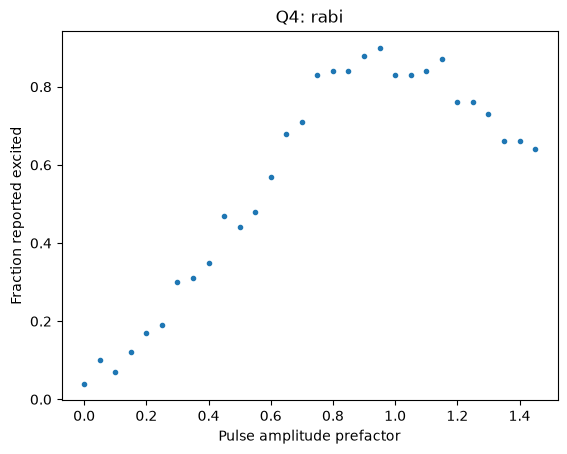

In [3]:
def plot_rawdata(RAW_PATH,QUBIT,EXPERIMENT):
    if RAW_PATH is None:
        print('Set RAW_PATH and QUBIT after collecting your data.')
    else:
        ds = load_raw(RAW_PATH)
        display(ds)
        print('Qubits:', ds.qubit.values)
        print('Coordinate units:', {name: coord.attrs.get('units') for name, coord in ds.coords.items()})
        if QUBIT is not None:
            x, y = raw_trace(ds, QUBIT, EXPERIMENT)
            plt.plot(x, y, 'o', ms=3)
            plt.xlabel('Idle time (us)' if EXPERIMENT == 't1' else 'Pulse amplitude prefactor')
            plt.ylabel('Fraction reported excited')
            plt.title(f'{QUBIT}: {EXPERIMENT}')
            plt.show()
    return
    
def get_full_path(runInfo):
    return 'data/'+runInfo+'/ds_raw.h5'
    #return '../qolab-start/qualibration_graphs/superconducting/calibrations/1Q_calibrations/data/'+runInfo+'/ds_raw.h5'
    
paths=["2026-10-11/#7_04b_power_rabi_231620","2026-10-11/#8_04b_power_rabi_232129","2026-10-12/#9_05_T1_123713","2026-10-13/#12_05_T1_165211","2026-10-13/#13_05_T1_165527"]
qubits=["Q4","Q6","Q4","Q6","Q6"]
for index in range(0,1):  #range(0,5) for all 5 plots
    RAW_PATH = get_full_path(paths[index]) # e.g. Path('my_data/my_run/ds_raw.h5')
    QUBIT = qubits[index]     # use an actual label shown by ds.qubit.values
    if 'T1' in paths[index]:
        EXPERIMENT = 't1'  # 'rabi' or 't1'
    else:
        EXPERIMENT = 'rabi'
    plot_rawdata(RAW_PATH,QUBIT,EXPERIMENT)

## 2. Power Rabi (9 points)
Answer parts (a)–(c) in the handout. Derive the pulse-area dependence, fit both raw traces to the supplied offset-plus-sinusoid model, report the pi-pulse prefactors, and show residuals. Explain your starting guesses and check whether the measured range supports the fitted maximum. Compare with the node's calibration without treating the observed maximum as a gate fidelity.

Write your model and fitting code below. `curve_fit` returns best-fit parameters and an approximate covariance matrix. An optimizer converging does not establish that your model is adequate.

<xarray.Dataset> Size: 736B
Dimensions:        (qubit: 1, nb_of_pulses: 1, amp_prefactor: 30)
Coordinates:
  * qubit          (qubit) <U2 8B 'Q4'
  * nb_of_pulses   (nb_of_pulses) int64 8B 1
  * amp_prefactor  (amp_prefactor) float64 240B 0.0 0.05 0.1 ... 1.35 1.4 1.45
    full_amp       (qubit, amp_prefactor) float64 240B 0.0 0.004405 ... 0.1278
Data variables:
    state          (qubit, nb_of_pulses, amp_prefactor) float64 240B 0.04 ......

Qubits: ['Q4']
Coordinate units: {'qubit': None, 'nb_of_pulses': None, 'amp_prefactor': None, 'full_amp': 'V'}
B  = 0.08548668540946816 ± 0.014236312810443628
C  = 0.7971245279650204 ± 0.02072276943242988
api = 1.0123404065231902 ± 0.00997786586075932


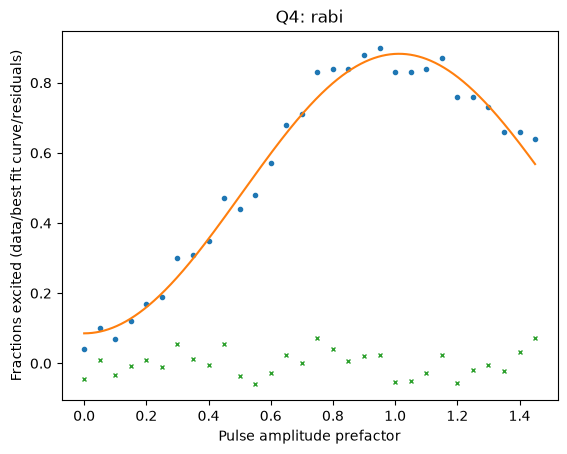

<xarray.Dataset> Size: 736B
Dimensions:        (qubit: 1, nb_of_pulses: 1, amp_prefactor: 30)
Coordinates:
  * qubit          (qubit) <U2 8B 'Q6'
  * nb_of_pulses   (nb_of_pulses) int64 8B 1
  * amp_prefactor  (amp_prefactor) float64 240B 0.0 0.05 0.1 ... 1.35 1.4 1.45
    full_amp       (qubit, amp_prefactor) float64 240B 0.0 0.004743 ... 0.1376
Data variables:
    state          (qubit, nb_of_pulses, amp_prefactor) float64 240B 0.1 ... ...

Qubits: ['Q6']
Coordinate units: {'qubit': None, 'nb_of_pulses': None, 'amp_prefactor': None, 'full_amp': 'V'}
B  = 0.06526987652905397 ± 0.01592608360016145
C  = 0.8321057098719519 ± 0.023238569962762967
api = 1.0032344194777987 ± 0.010354527598974228


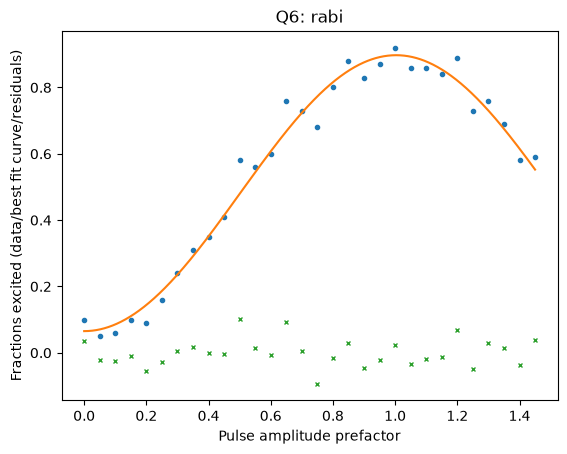

In [4]:
from scipy.optimize import curve_fit

def model(a, B, C, api):
    return B + C * np.sin(np.pi * a / (2 * api))**2

def plot_rabi_run(runIndex):
    path=get_full_path(paths[runIndex])
    qubit=qubits[runIndex]
    
    ds = load_raw(path)
    display(ds)
    a, Pe = raw_trace(ds, qubit, "rabi")
    print('Qubits:', ds.qubit.values)
    print('Coordinate units:', {name: coord.attrs.get('units') for name, coord in ds.coords.items()})
    
    initial_guess = [Pe[0], Pe.max() - Pe[0], a[np.argmax(Pe)]]
    best_fit_params, pcov = curve_fit(model, a, Pe, p0=initial_guess, bounds=([0, 0, 0], [np.inf, np.inf, np.inf]))
    uncertainties = np.sqrt(np.diag(pcov))
    
    B, C, api = best_fit_params
    print(f"B  = {B} ± {uncertainties[0]}")
    print(f"C  = {C} ± {uncertainties[1]}")
    print(f"api = {api} ± {uncertainties[2]}")
    
    a_smooth=np.linspace(a.min(),a.max(),1000)
    Pe_smooth=model(a_smooth,B,C,api)
    residuals= Pe - model(a, B, C, api)
    
    plt.plot(a, Pe, 'o', ms=3)
    plt.plot(a_smooth, Pe_smooth, '-',ms=3)
    plt.plot(a, residuals, 'x', ms=3)
    plt.xlabel('Pulse amplitude prefactor')
    plt.ylabel('Fractions excited (data/best fit curve/residuals)')
    plt.title(f'{qubit}: rabi')
    plt.show()
    return
plot_rabi_run(0)
plot_rabi_run(1)

## 3. T1 and initialization (9 points)
Answer parts (a)–(c). Fit both raw traces to $s(t)=B+A e^{-t/T_1}$ with a free baseline and contrast, using time in microseconds. Show fit curves and residuals, explain your initial guesses, and discuss whether the time window resolves the decay and baseline.

Use the fitted T1 values to calculate the idealized 1% reset waits and the residual after 5T1. Relate your fitted A and B to the thermal relaxation and imperfect-readout model in the handout; do not equate the reported excitation fraction with the true excited-state population without justification.

**Before each baseline T1 run:** use the repository's state manager to store a local checkpoint, with a distinct label identifying that run. From the repository terminal: `uv run python manage_state_and_wiring.py store state --label before-my-t1`. This stores the active local state; it does not upload to the cloud. For Problem 4, restore the checkpoint associated with the trace you are repeating, using `uv run python manage_state_and_wiring.py load state --source local` and selecting that stored label. Check the active project and selected checkpoint before confirming. Do not use the `upload` command.

<xarray.Dataset> Size: 2kB
Dimensions:    (qubit: 1, idle_time: 100)
Coordinates:
  * qubit      (qubit) <U2 8B 'Q4'
  * idle_time  (idle_time) int64 800B 16 2036 4056 6076 ... 195956 197976 200000
Data variables:
    state      (qubit, idle_time) float64 800B 0.91 0.83 0.76 ... 0.12 0.22 0.14

Qubits: ['Q4']
Coordinate units: {'qubit': None, 'idle_time': 'ns'}
A  = 0.7914423112950105 ± 0.019186707519014027
B  = 0.0863573371124116 ± 0.021092221057411775
T1 = 76.93636339270891 ± 5.879125579222233


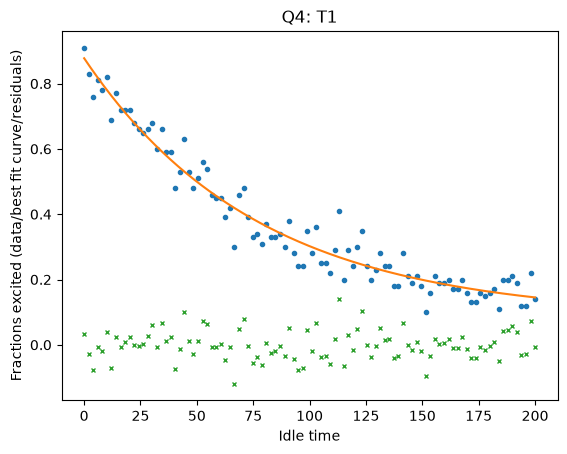

<xarray.Dataset> Size: 2kB
Dimensions:    (qubit: 1, idle_time: 100)
Coordinates:
  * qubit      (qubit) <U2 8B 'Q6'
  * idle_time  (idle_time) int64 800B 16 2036 4056 6076 ... 195956 197976 200000
Data variables:
    state      (qubit, idle_time) float64 800B 0.95 0.88 0.87 ... 0.14 0.17 0.16

Qubits: ['Q6']
Coordinate units: {'qubit': None, 'idle_time': 'ns'}
A  = 0.7913706086904946 ± 0.02038667103979314
B  = 0.088925466433601 ± 0.023466404882688332
T1 = 82.54661622335904 ± 6.644342135919981


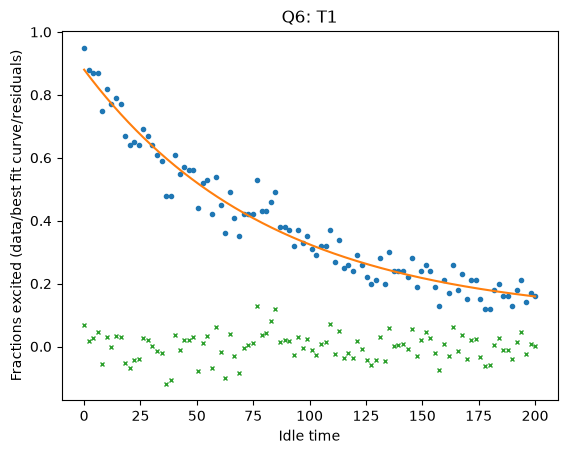

In [5]:
def t1_model(t, A, B, T1):
    return B + A * np.exp(-t/T1)

def plot_t1_run(runIndex):
    path=get_full_path(paths[runIndex])
    qubit=qubits[runIndex]
    
    ds = load_raw(path)
    display(ds)
    t, Pe = raw_trace(ds, qubit, "t1")
    print('Qubits:', ds.qubit.values)
    print('Coordinate units:', {name: coord.attrs.get('units') for name, coord in ds.coords.items()})

    init_B = Pe.min()
    init_A = Pe.max() - init_B
    Pe_T1 = init_B + init_A/np.e
    init_T1 = np.argmin(np.abs(Pe - Pe_T1))
    
    initial_guess = [init_A, init_B, init_T1]
    best_fit_params, pcov = curve_fit(t1_model, t, Pe, p0=initial_guess, bounds=([0, 0, 0], [np.inf, np.inf, np.inf]))
    uncertainties = np.sqrt(np.diag(pcov))
    
    A, B, T1 = best_fit_params
    print(f"A  = {A} ± {uncertainties[0]}")
    print(f"B  = {B} ± {uncertainties[1]}")
    print(f"T1 = {T1} ± {uncertainties[2]}")
    
    t_smooth=np.linspace(t.min(),t.max(),1000)
    Pe_smooth=t1_model(t_smooth,A,B,T1)
    residuals= Pe - t1_model(t, A , B, T1)
    
    plt.plot(t, Pe, 'o', ms=3)
    plt.plot(t_smooth, Pe_smooth, '-',ms=3)
    plt.plot(t, residuals, 'x', ms=3)
    plt.xlabel('Idle time')
    plt.ylabel('Fractions excited (data/best fit curve/residuals)')
    plt.title(f'{qubit}: T1')
    plt.show()
    return
plot_t1_run(2)
plot_t1_run(3)

## 4. Controlled follow-up (6 points)
Before the repeat run, record your prediction for increasing the shots per point from 100 to 400. Repeat one T1 trace, keeping the initial calibration state and other settings fixed. Save the new dataset separately.

Then compare both independent fits, contrasts, baselines, and residual scatter. Distinguish sampling fluctuations from drift or systematic errors, and propose one further diagnostic without collecting additional data.

**Prediction recorded before collection:**

**Observed result and interpretation:**

<xarray.Dataset> Size: 2kB
Dimensions:    (qubit: 1, idle_time: 100)
Coordinates:
  * qubit      (qubit) <U2 8B 'Q6'
  * idle_time  (idle_time) int64 800B 16 2036 4056 6076 ... 195956 197976 200000
Data variables:
    state      (qubit, idle_time) float64 800B 0.9275 0.8725 ... 0.135 0.1175

Qubits: ['Q6']
Coordinate units: {'qubit': None, 'idle_time': 'ns'}
A  = 0.8046640854352066 ± 0.009635862849689125
B  = 0.08135989946411207 ± 0.010960225991172644
T1 = 80.83380745417449 ± 3.0374623540555987


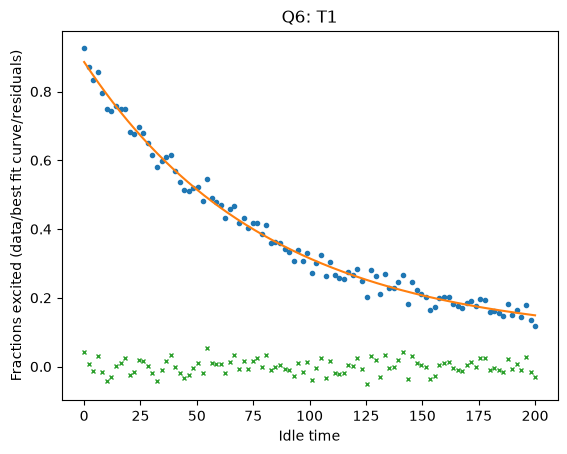

In [6]:
plot_t1_run(4)